# FlavourNet: from coffee shop reviews to a knowledge graph

This notebook turns 10,000 Yelp reviews of Coffee & Tea businesses into a network of concepts (drinks, food, service, ambience, quality words) and the relationships customers draw between them, then analyses that network.

Pipeline: **preprocess → extract concepts (TF-IDF, YAKE, spaCy NER) → extract relationships (dependency parsing) → filter by PMI → build the graph → centrality, communities and sentiment**.

Input: `data/coffee_tea_sample.csv`, built from the Yelp Open Dataset by `python src/build_sample.py` (the reviews themselves are not redistributed; see the README).

In [1]:
import math
import re
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import community as community_louvain  # python-louvain
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import spacy
import yake
from sklearn.feature_extraction.text import TfidfVectorizer
from textblob import TextBlob
from wordcloud import WordCloud

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUTPUTS = ROOT / "data", ROOT / "outputs"
OUTPUTS.mkdir(exist_ok=True)

nlp = spacy.load("en_core_web_sm")
SEED = 42

## 1. Load and preprocess the reviews

Lower-case, strip everything that is not a letter, then lemmatise with spaCy and drop stop words and tokens of two letters or fewer. `clean_text` feeds TF-IDF; the raw text is kept for YAKE, NER and dependency parsing, which need real sentences.

In [2]:
reviews = pd.read_csv(DATA / "coffee_tea_sample.csv")
print(f"{len(reviews):,} reviews from {reviews.business_name.nunique():,} businesses in "
      f"{reviews.state.nunique()} states, {reviews.date.min()[:4]}-{reviews.date.max()[:4]}")
reviews.stars.value_counts().sort_index()

10,000 reviews from 2,192 businesses in 15 states, 2006-2022


stars
1    1155
2     700
3    1001
4    2157
5    4987
Name: count, dtype: int64

In [3]:
def preprocess(doc):
    return [t.lemma_ for t in doc
            if not t.is_stop and not t.is_punct and not t.is_space and t.is_alpha and len(t.text) > 2]

cleaned = (re.sub(r"[^a-zA-Z\s]", " ", str(t).lower()) for t in reviews.text)
reviews["tokens"] = [preprocess(doc) for doc in nlp.pipe(cleaned, batch_size=200)]
reviews["clean_text"] = reviews.tokens.str.join(" ")
print("Example tokens:", reviews.tokens[0][:10])

Example tokens: ['try', 'chill', 'grade', 'paper', 'couldn', 'employee', 'sit', 'play', 'phone', 'loud']


## 2. Concept extraction

Three complementary methods, combined into one vocabulary of concepts:

- **TF-IDF** (top 300 unigrams and bigrams) finds terms that characterise individual reviews
- **YAKE** finds key phrases in each raw review without needing a corpus; the 100 most frequent are kept
- **spaCy NER** picks up named things: brands, places and products (top 50)

In [4]:
tfidf = TfidfVectorizer(max_features=300, ngram_range=(1, 2), min_df=5, max_df=0.85)
tfidf_matrix = tfidf.fit_transform(reviews.clean_text).tocsr()
terms = tfidf.get_feature_names_out()
tfidf_keywords = set(terms)

tfidf_per_review = pd.DataFrame(
    [{"review_id": reviews.review_id.iat[i], "concept": terms[j], "tfidf_score": round(s, 6)}
     for i in range(tfidf_matrix.shape[0])
     for j, s in zip(tfidf_matrix[i].indices, tfidf_matrix[i].data)])
tfidf_global = (tfidf_per_review.groupby("concept").tfidf_score.mean()
                .sort_values(ascending=False).rename("mean_tfidf").reset_index())
concept_importance = dict(zip(tfidf_global.concept, tfidf_global.mean_tfidf))

print(f"TF-IDF concepts: {len(tfidf_keywords)}")
print("Highest mean TF-IDF:", tfidf_global.concept.head(15).tolist())

TF-IDF concepts: 300
Highest mean TF-IDF: ['gelato', 'donut', 'crepe', 'beignet', 'boba', 'bagel', 'burger', 'bowl', 'biscuit', 'ice cream', 'croissant', 'pancake', 'cake', 'vegan', 'tea']


In [5]:
kw_extractor = yake.KeywordExtractor(lan="en", n=2, dedupLim=0.7, top=15)
yake_df = pd.DataFrame(
    [{"review_id": rid, "concept": kw.lower(), "yake_importance": round(1 - score, 4)}
     for rid, text in zip(reviews.review_id, reviews.text)
     for kw, score in kw_extractor.extract_keywords(str(text))])
yake_freq = Counter(yake_df.concept)
top_yake = {kw for kw, _ in yake_freq.most_common(100)}
print(f"YAKE concepts: {len(top_yake)}")
pd.Series(dict(yake_freq.most_common(15)), name="reviews").to_frame().T

YAKE concepts: 100


,place,coffee,great,food,good,service,love,time,breakfast,delicious,friendly,staff,amazing,nice,order
reviews,2318,2307,1717,1640,1552,1051,861,830,788,781,706,677,635,590,551


In [6]:
NER_LABELS = {"ORG", "PRODUCT", "GPE", "FAC", "NORP"}
reviews["ner_entities"] = [[(e.text.lower(), e.label_) for e in doc.ents if e.label_ in NER_LABELS]
                           for doc in nlp.pipe(reviews.text.astype(str), batch_size=200)]
ner_freq = Counter(e for ents in reviews.ner_entities for e, _ in ents)
top_ner = {e for e, _ in ner_freq.most_common(50)}

all_concepts = tfidf_keywords | top_yake | top_ner
token_freq = Counter(t for tokens in reviews.tokens for t in tokens)
print(f"NER entities: {len(top_ner)}  ->  combined vocabulary: {len(all_concepts)} concepts")

NER entities: 50  ->  combined vocabulary: 361 concepts


Each concept gets a type from a hand-built coffee-shop lexicon. Anything not in the lexicon is a general `CONCEPT`.

In [7]:
ENTITY_CATEGORIES = {
    "DRINK": {"coffee", "espresso", "latte", "cappuccino", "matcha", "tea", "americano", "mocha", "chai",
              "cortado", "flat white", "macchiato", "frappuccino", "cold brew", "iced coffee", "boba", "taro",
              "hot chocolate", "juice", "smoothie"},
    "FOOD": {"pastry", "croissant", "bagel", "sandwich", "cake", "muffin", "toast", "cookie", "waffle", "scone",
             "pancake", "egg", "donut", "biscuit", "quiche", "granola", "oatmeal", "brownie", "salad", "wrap",
             "avocado", "cream", "cheese", "bread", "chicken"},
    "SERVICE": {"barista", "staff", "service", "server", "cashier", "friendly", "attentive", "helpful",
                "efficient", "rude", "slow", "fast", "wait", "queue", "order"},
    "AMBIENCE": {"atmosphere", "ambience", "cozy", "noisy", "quiet", "seating", "decor", "music", "lighting",
                 "outdoor", "indoor", "wifi", "space", "parking", "clean", "busy", "crowded"},
    "EXPERIENCE": {"work", "study", "morning", "weekend", "visit", "brunch", "lunch", "breakfast", "relax",
                   "hangout", "date", "meeting"},
    "QUALITY": {"good", "great", "delicious", "amazing", "fresh", "hot", "cold", "sweet", "excellent",
                "awesome", "perfect", "strong", "weak", "expensive", "cheap", "bad", "terrible", "poor", "warm",
                "bitter", "tasty", "wonderful", "crispy", "fluffy", "creamy", "rich", "smooth", "bold", "mild",
                "overpriced", "affordable", "outstanding", "mediocre", "decent", "disappointing"},
}
CONCEPT_TYPE = {w: cat for cat, words in ENTITY_CATEGORIES.items() for w in words}

def get_type(concept):
    return CONCEPT_TYPE.get(concept.lower(), "CONCEPT")

concepts_df = (pd.DataFrame([{"concept": c, "frequency": token_freq.get(c, 0), "entity_type": get_type(c)}
                             for c in all_concepts])
               .sort_values("frequency", ascending=False, ignore_index=True))
concepts_df.entity_type.value_counts()

entity_type
CONCEPT       299
QUALITY        16
FOOD           15
SERVICE        11
AMBIENCE        8
EXPERIENCE      7
DRINK           5
Name: count, dtype: int64

## 3. Relationship extraction

For every sentence, each token whose grammatical link to its head is one of a set of useful dependency types (adjective modifier, subject, object, compound, preposition, attribute, conjunction) becomes a candidate edge **token → head**, kept only if both ends are in the concept vocabulary. The dependency type names the relation, so *"friendly staff"* gives `friendly --described_as--> staff`.

In [8]:
VALID_DEPS = {"amod", "nsubj", "nsubjpass", "dobj", "compound", "prep", "pobj", "attr", "conj"}
SKIP = {"the", "and", "but", "for", "not", "are", "was"}

def classify_relation(subj, obj, dep):
    if dep == "amod": return "described_as"
    if dep == "nsubj": return "has_property"
    if dep == "dobj": return "relates_to"
    if dep == "compound": return "associated_with"
    if dep in ("prep", "pobj"): return "connected_to"
    st, ot = get_type(subj), get_type(obj)
    if st == "QUALITY" and ot in ("DRINK", "FOOD", "SERVICE"): return "describes"
    if ot == "QUALITY" and st in ("DRINK", "FOOD", "SERVICE"): return "has_quality"
    if st in ("DRINK", "FOOD") and ot in ("DRINK", "FOOD"): return "associated_with"
    if st in ("DRINK", "FOOD") and ot == "SERVICE": return "served_by"
    if st in ("SERVICE", "AMBIENCE") and ot == "EXPERIENCE": return "affects"
    return "relates_to"

dep_edges = defaultdict(lambda: {"count": 0, "reviews": set(), "relations": Counter()})
for rid, doc in zip(reviews.review_id, nlp.pipe(reviews.text.astype(str), batch_size=200)):
    for token in doc:
        if token.dep_ not in VALID_DEPS:
            continue
        subj, obj = token.lemma_.lower().strip(), token.head.lemma_.lower().strip()
        if (subj not in all_concepts or obj not in all_concepts or subj == obj
                or len(subj) < 3 or len(obj) < 3 or subj in SKIP):
            continue
        e = dep_edges[subj, obj]
        e["count"] += 1
        e["reviews"].add(rid)
        e["relations"][classify_relation(subj, obj, token.dep_)] += 1
print(f"Candidate concept pairs: {len(dep_edges):,}")

Candidate concept pairs: 12,829


### Filtering with PMI

Most candidate pairs are noise or simply two very common words. **Pointwise mutual information** compares how often two concepts appear in the same review with how often they would by chance: PMI > 0 means they co-occur more than expected. An edge is kept if PMI > 0 and it is seen at least twice, in at least two different reviews.

In [9]:
dep_df = pd.DataFrame([{
    "source": s, "target": t,
    "relation": d["relations"].most_common(1)[0][0],
    "extraction_method": "dependency_parsing",
    "source_type": get_type(s), "target_type": get_type(t),
    "weight": d["count"], "review_count": len(d["reviews"]),
} for (s, t), d in dep_edges.items()])

concept_reviews = tfidf_per_review.groupby("concept").review_id.nunique().to_dict()
n_reviews = tfidf_per_review.review_id.nunique()

def pmi(row):
    p_xy = row.review_count / n_reviews
    p_x = concept_reviews.get(row.source, 1) / n_reviews
    p_y = concept_reviews.get(row.target, 1) / n_reviews
    return round(math.log2(p_xy / (p_x * p_y)), 4)

dep_df["pmi_score"] = dep_df.apply(pmi, axis=1)
dep_df["source_importance"] = dep_df.source.map(concept_importance).fillna(0).round(6)
dep_df["target_importance"] = dep_df.target.map(concept_importance).fillna(0).round(6)

edges = dep_df[(dep_df.pmi_score > 0) & (dep_df.weight >= 2) & (dep_df.review_count >= 2)].reset_index(drop=True)
w = edges.weight
edges["normalized_weight"] = ((w - w.min()) / (w.max() - w.min())).round(6)

print(f"{len(dep_df):,} candidate edges -> {len(edges)} after the PMI filter")
print(edges.relation.value_counts().to_string())
edges.sort_values("weight", ascending=False)[["source", "relation", "target", "weight", "pmi_score"]].head(12)

12,829 candidate edges -> 355 after the PMI filter
relation
relates_to         141
described_as       104
associated_with     82
has_property        26
connected_to         2


,source,relation,target,weight,pmi_score
2,coffee,associated_with,shop,760,0.7247
41,ice,associated_with,cream,538,2.9169
8,customer,associated_with,service,386,0.9390
21,order,relates_to,take,251,0.0630
73,breakfast,associated_with,sandwich,230,0.3790
69,place,has_property,have,214,1.0265
29,french,described_as,toast,199,3.2741
17,iced,described_as,coffee,196,0.2841
36,star,relates_to,give,185,2.1772
87,milk,associated_with,tea,169,1.4244


## 4. The knowledge graph

A directed graph: nodes are concepts (with type, frequency and TF-IDF importance), edges are the filtered relationships.

In [10]:
G = nx.DiGraph()
for node in set(edges.source) | set(edges.target):
    G.add_node(node, entity_type=get_type(node), frequency=token_freq.get(node, 0),
               importance=round(concept_importance.get(node, 0), 6))
for r in edges.itertuples():
    G.add_edge(r.source, r.target, relation=r.relation, weight=r.weight, pmi_score=r.pmi_score,
               normalized_weight=r.normalized_weight, review_count=r.review_count,
               source_type=r.source_type, target_type=r.target_type)

print(f"Nodes {G.number_of_nodes()}, edges {G.number_of_edges()}, density {nx.density(G):.4f}")
pd.Series(Counter(nx.get_node_attributes(G, "entity_type").values())).sort_values(ascending=False)

Nodes 219, edges 355, density 0.0074


CONCEPT       174
FOOD           15
SERVICE         8
AMBIENCE        6
QUALITY         6
EXPERIENCE      5
DRINK           5
dtype: int64

## 5. Network analysis

- **Degree centrality**: how many other concepts a concept is linked to
- **Betweenness**: how often it sits on the shortest path between two others, i.e. bridges between themes
- **PageRank**: importance that also counts who links to you
- **Louvain communities** on the undirected graph: groups of concepts that talk to each other more than to the rest (seeded, so the result is reproducible)

In [11]:
degree = nx.degree_centrality(G)
metrics = pd.DataFrame({
    "degree": degree,
    "in_degree": nx.in_degree_centrality(G),
    "out_degree": nx.out_degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G, weight="weight"),
    "closeness": nx.closeness_centrality(G),
    "pagerank": nx.pagerank(G, weight="weight"),
}).round(6)
partition = community_louvain.best_partition(G.to_undirected(), random_state=SEED)
metrics["community"] = pd.Series(partition)
metrics.insert(0, "entity_type", [G.nodes[n]["entity_type"] for n in metrics.index])
metrics.insert(1, "frequency", [G.nodes[n]["frequency"] for n in metrics.index])
metrics = metrics.rename_axis("concept").sort_values("degree", ascending=False).reset_index()

n_communities = metrics.community.nunique()
print(f"Communities: {n_communities}")
metrics.head(15)

Communities: 26


,concept,entity_type,frequency,degree,in_degree,out_degree,betweenness,closeness,pagerank,community
0,have,CONCEPT,271,0.522936,0.513761,0.009174,0.007187,0.570779,0.312932,22
1,starbucks,CONCEPT,41,0.110092,0.041284,0.068807,0.004291,0.039646,0.011801,22
2,cuban,CONCEPT,179,0.068807,0.004587,0.064220,0.000507,0.004587,0.001440,8
3,italian,CONCEPT,146,0.059633,0.004587,0.055046,0.000465,0.004587,0.001294,8
4,caramel,CONCEPT,167,0.059633,0.009174,0.050459,0.002198,0.015013,0.001404,10
5,coffee,DRINK,6356,0.059633,0.045872,0.013761,0.001057,0.062910,0.005849,13
6,food,CONCEPT,4234,0.055046,0.050459,0.004587,0.000000,0.052887,0.005195,8
7,thai,CONCEPT,89,0.041284,0.004587,0.036697,0.000613,0.004587,0.001326,7
8,sandwich,FOOD,1616,0.036697,0.027523,0.009174,0.001501,0.036327,0.005619,8
9,restaurant,CONCEPT,894,0.036697,0.032110,0.004587,0.000095,0.033778,0.002592,8


In [12]:
print("Bridge concepts (highest betweenness):")
metrics.sort_values("betweenness", ascending=False)[["concept", "entity_type", "betweenness", "community"]].head(10)

Bridge concepts (highest betweenness):


,concept,entity_type,betweenness,community
0,have,CONCEPT,0.007187,22
1,starbucks,CONCEPT,0.004291,22
4,caramel,CONCEPT,0.002198,10
20,turkey,CONCEPT,0.001955,11
8,sandwich,FOOD,0.001501,8
37,cheese,FOOD,0.001194,1
29,cream,FOOD,0.001184,1
21,bacon,CONCEPT,0.001068,1
27,egg,FOOD,0.001057,1
5,coffee,DRINK,0.001057,13


In [13]:
community_df = (metrics.groupby("community")
                .apply(lambda g: pd.Series({
                    "size": len(g),
                    "top_concepts": ", ".join(g.nlargest(8, "degree").concept),
                    "dominant_type": g.entity_type.mode().iat[0],
                    "type_breakdown": str(g.entity_type.value_counts().to_dict()),
                }), include_groups=False)
                .rename_axis("community_id").reset_index()
                .sort_values("size", ascending=False))
community_df.head(10)

,community_id,size,top_concepts,dominant_type,type_breakdown
22,22,96,"have, starbucks, area, place, experience, tamp...",CONCEPT,"{'CONCEPT': 81, 'FOOD': 5, 'AMBIENCE': 5, 'SER..."
8,8,20,"cuban, italian, food, sandwich, restaurant, sa...",CONCEPT,"{'CONCEPT': 14, 'FOOD': 4, 'QUALITY': 1, 'EXPE..."
10,10,9,"caramel, chocolate, sauce, pecan, cake, get, c...",CONCEPT,"{'CONCEPT': 6, 'FOOD': 2, 'QUALITY': 1}"
4,4,9,"visit, philadelphia, nashville, nola, tucson, ...",CONCEPT,"{'CONCEPT': 8, 'EXPERIENCE': 1}"
0,0,8,"yelp, review, say, thank, use, tell, check, read",CONCEPT,{'CONCEPT': 8}
11,11,8,"fry, turkey, soup, burger, french, toast, pota...",CONCEPT,"{'CONCEPT': 7, 'FOOD': 1}"
1,1,7,"bacon, egg, cream, american, cheese, ice, cook",CONCEPT,"{'CONCEPT': 4, 'FOOD': 3}"
13,13,6,"coffee, latte, shop, iced, carmel, times",CONCEPT,"{'CONCEPT': 4, 'DRINK': 2}"
6,6,6,"fan, portion, large, huge, size, big",CONCEPT,{'CONCEPT': 6}
7,7,6,"thai, tea, milk, boba, bean, green",CONCEPT,"{'CONCEPT': 4, 'DRINK': 2}"


## 6. Sentiment

TextBlob polarity on the raw text (−1 to +1), bucketed at ±0.1.

In [14]:
reviews["polarity"] = [round(TextBlob(str(t)).sentiment.polarity, 3) for t in reviews.text]
reviews["sentiment"] = pd.cut(reviews.polarity, [-1.01, -0.1, 0.1, 1.01], labels=["negative", "neutral", "positive"])
pd.crosstab(reviews.stars, reviews.sentiment, normalize="index").round(2)

sentiment,negative,neutral,positive
stars,,,
1,0.40,0.42,0.18
2,0.15,0.46,0.39
3,0.04,0.26,0.70
4,0.00,0.09,0.91
5,0.00,0.05,0.95


## 7. Figures

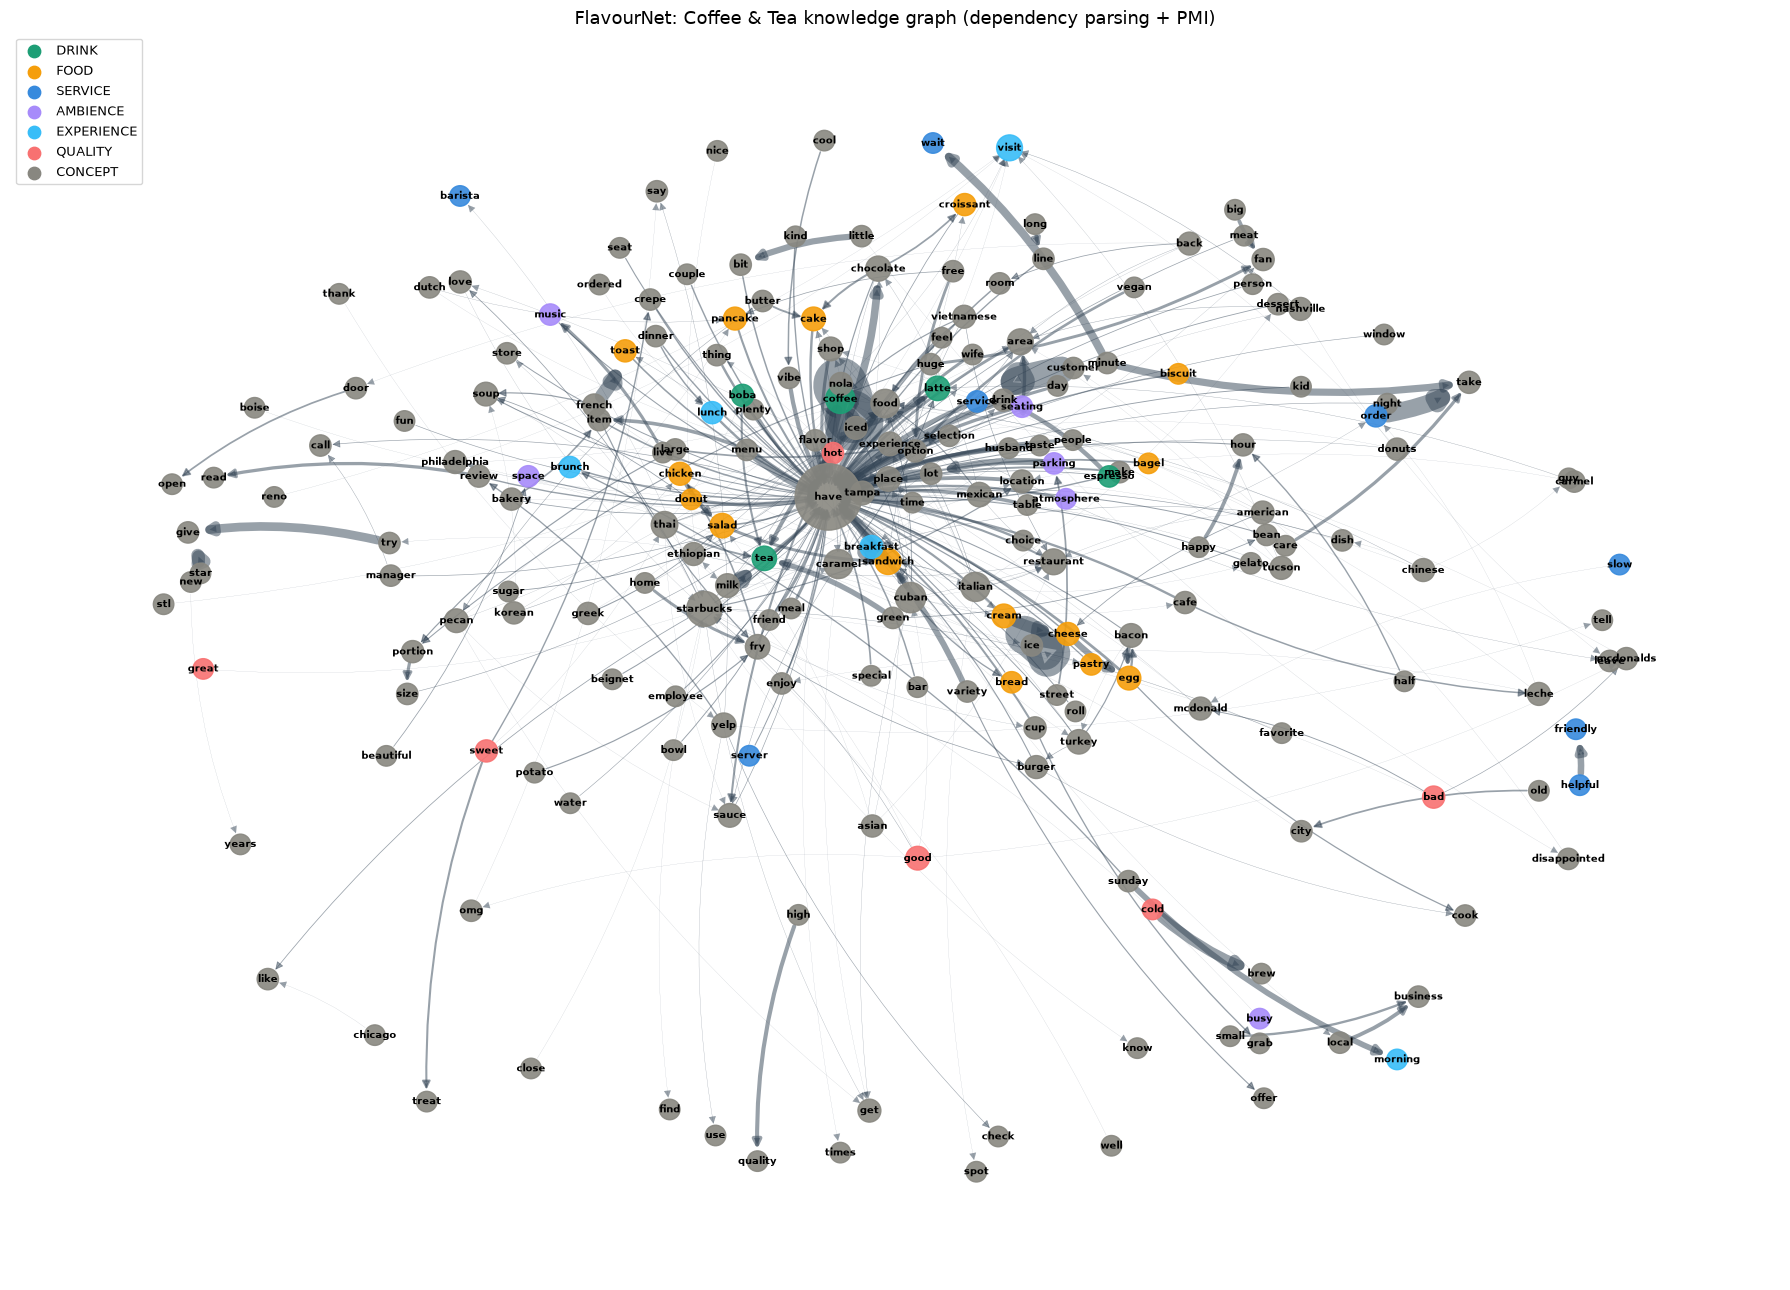

In [15]:
TYPE_COLORS = {"DRINK": "#1D9E75", "FOOD": "#f59e0b", "SERVICE": "#378ADD", "AMBIENCE": "#a78bfa",
               "EXPERIENCE": "#38bdf8", "QUALITY": "#f87171", "CONCEPT": "#888780"}

plt.figure(figsize=(18, 13))
pos = nx.spring_layout(G, seed=SEED, k=0.8)
nx.draw_networkx_nodes(G, pos, node_color=[TYPE_COLORS[G.nodes[n]["entity_type"]] for n in G],
                       node_size=[200 + degree[n] * 4000 for n in G], alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=7, font_weight="bold")
nx.draw_networkx_edges(G, pos, edge_color="#334455", width=[G[u][v]["weight"] * 0.05 for u, v in G.edges],
                       arrows=True, arrowsize=12, alpha=0.5, connectionstyle="arc3,rad=0.1")
for t, c in TYPE_COLORS.items():
    plt.scatter([], [], c=c, label=t, s=80)
plt.legend(loc="upper left", fontsize=9)
plt.title("FlavourNet: Coffee & Tea knowledge graph (dependency parsing + PMI)", fontsize=13)
plt.axis("off"); plt.tight_layout()
plt.savefig(OUTPUTS / "flavournet_knowledge_graph.png", dpi=150); plt.show()

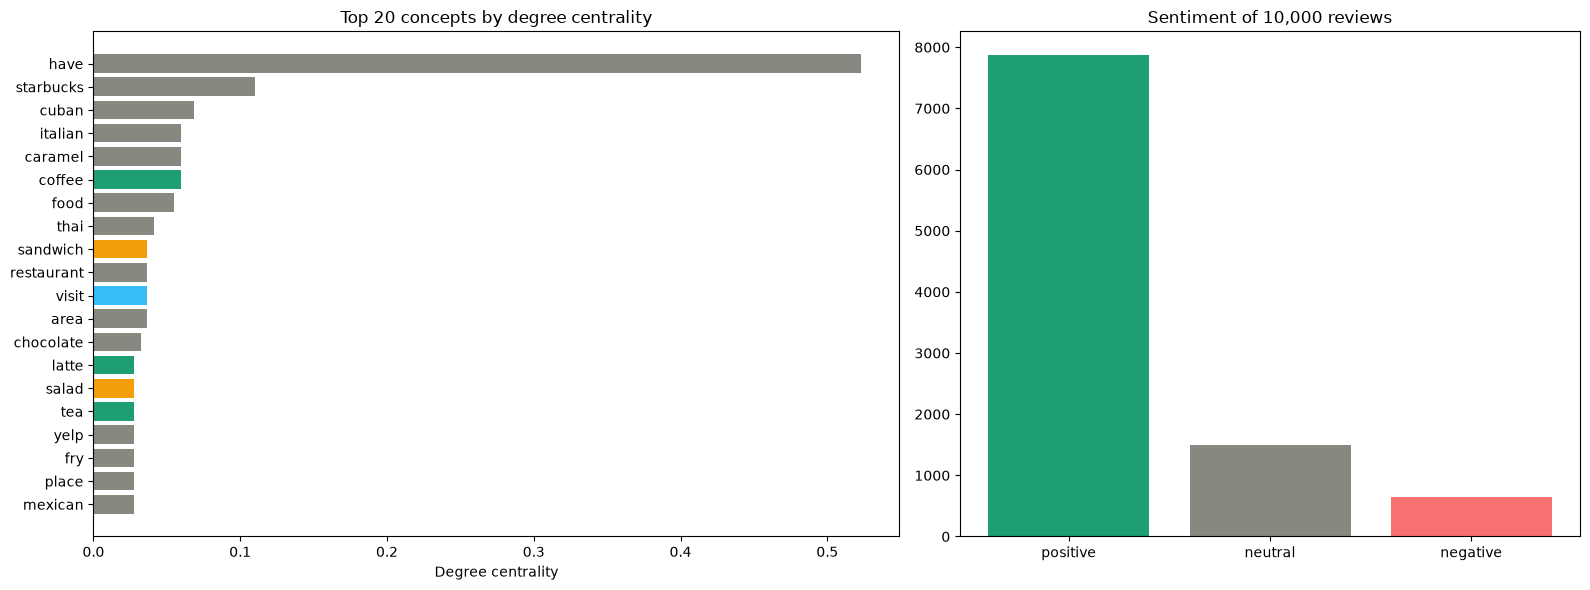

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1]})
top = metrics.head(20).iloc[::-1]
ax1.barh(top.concept, top.degree, color=[TYPE_COLORS[t] for t in top.entity_type])
ax1.set_title("Top 20 concepts by degree centrality"); ax1.set_xlabel("Degree centrality")
counts = reviews.sentiment.value_counts().reindex(["positive", "neutral", "negative"])
ax2.bar(counts.index, counts.values, color=["#1D9E75", "#888780", "#f87171"])
ax2.set_title(f"Sentiment of {len(reviews):,} reviews")
plt.tight_layout(); plt.savefig(OUTPUTS / "flavournet_centrality_sentiment.png", dpi=150); plt.show()

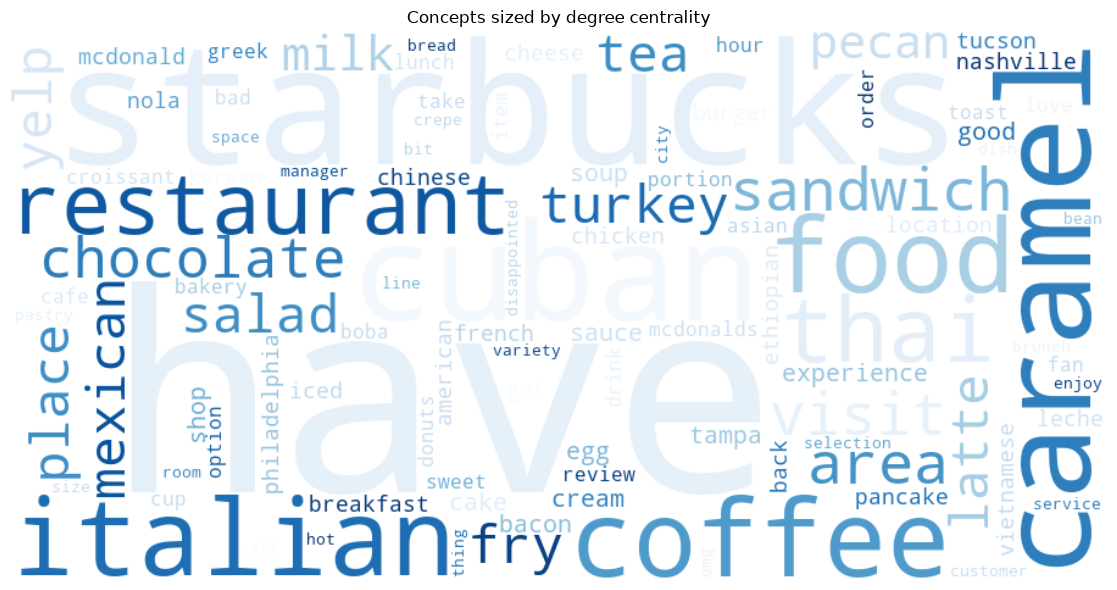

In [17]:
wc = WordCloud(width=900, height=450, background_color="white", colormap="Blues", max_words=100,
               random_state=SEED).generate_from_frequencies(degree)
plt.figure(figsize=(13, 6)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Concepts sized by degree centrality")
plt.tight_layout(); plt.savefig(OUTPUTS / "flavournet_wordcloud.png", dpi=150); plt.show()

## 8. Save the outputs

These files are what the dashboard (`python dashboard/app.py`) reads.

In [18]:
nx.write_graphml(G, DATA / "flavournet_knowledge_graph.graphml")
edges.to_csv(DATA / "relationships_final.csv", index=False)
metrics.to_csv(DATA / "flavournet_node_metrics.csv", index=False)
community_df.to_csv(DATA / "flavournet_community_summary.csv", index=False)
concepts_df.to_csv(DATA / "concepts.csv", index=False)

print(f"Reviews {len(reviews):,} | concepts {len(all_concepts)} | nodes {G.number_of_nodes()} | "
      f"edges {G.number_of_edges()} | communities {n_communities} | relation types {edges.relation.nunique()}")

Reviews 10,000 | concepts 361 | nodes 219 | edges 355 | communities 26 | relation types 5
